In [2]:
import numpy as np
from matplotlib import pyplot as plt
import cv2 as cv
import math

# Aufgabe 1
## a)

In [3]:
first  =[7, 9, 8, 44, 89]
second =[16, 4, 12, 91, 77]
third  =[11, 2, 6, 66, 58]
fourth =[22, 18, 5, 39, 76]
fifth  =[23, 13, 44, 84, 49]

In [4]:
mat = np.array([first,second,third,fourth,fifth])

In [5]:
mat

array([[ 7,  9,  8, 44, 89],
       [16,  4, 12, 91, 77],
       [11,  2,  6, 66, 58],
       [22, 18,  5, 39, 76],
       [23, 13, 44, 84, 49]])

In [6]:
mati = np.matrix('7 9 8 44 89; 16 4 12 91 77; 11 2 6 66 58; 22 18 5 39 76; 23 13 44 84 49')

In [7]:
def bilateral(matrix, x, y, sigS, sigR):
    x_mat,y_mat = matrix.shape

    wert= matrix[x,y]

    zähler = 0
    nenner = 0

    for j in range(y_mat):
        for i in range(x_mat):
            w1 = math.exp(-((i-x)**2+(j-y)**2)/(2*sigS**2))

            w2 = math.exp(-(matrix[i,j]-wert)**2/(2*sigR**2))

            zähler += ((w1*w2)*matrix[i,j])
            nenner += (w1*w2)
        
    return zähler/nenner

In [8]:
bilateral(mati,2,2,0.9,15)

np.float64(7.537998591842697)

## b)

In [9]:
house = cv.imread("/home/farouk/Uni/3. Semester/Bildverarbeitung/Bilder/GruenesHaus.jpg")
gruenes_house= cv.cvtColor(house, cv.COLOR_BGR2RGB)

In [10]:
def show_image(img, title):
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

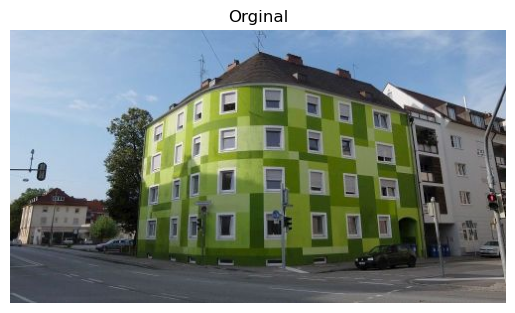

In [11]:
show_image(gruenes_house, 'Orginal')

In [12]:
import cv2

def add_gaussian_noise(image,std):
    image_float = image.astype(np.float32)
    noise = np.random.normal(0, std, image_float.shape).astype(np.float32)
    noisy_image = cv2.add(image_float, noise)
    noisy_image = np.clip(noisy_image, 0, 255)
    noisy_image = noisy_image.astype(np.uint8)
    show_image(noisy_image,"noised image")

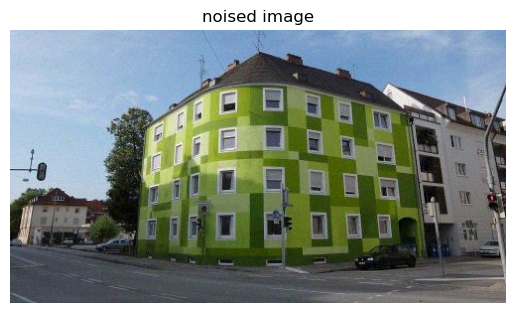

In [15]:
add_gaussian_noise(gruenes_house,5)

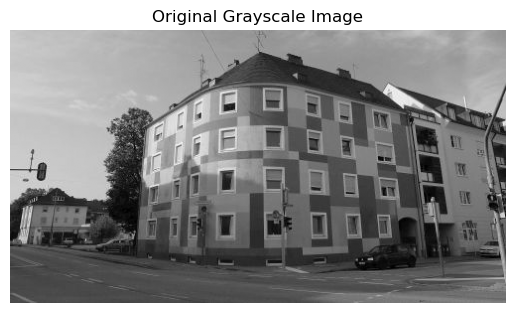

In [17]:
gray_house= cv.cvtColor(house, cv.COLOR_BGR2GRAY)
show_image(gray_house, "Original Grayscale Image")

In [28]:
def saltPepper(bild,verteilung,menge):
  ausgabe = bild
  salzmenge = np.ceil(menge * bild.size * verteilung)
  koordinaten = [np.random.randint(0, i-1, int(salzmenge)) for i in bild.shape]
  ausgabe[koordinaten] = 255

  pfeffermenge = np.ceil(menge * bild.size * (1.0-verteilung))
  koordinaten = [np.random.randint(0,i-1,int(pfeffermenge)) for i in bild.shape]
  ausgabe[koordinaten] = 0
  return ausgabe

In [29]:
saltPepper(gray_house,0.5,0.04)

IndexError: index 319 is out of bounds for axis 0 with size 275